In [32]:
import torch

In [33]:
from torch import nn


In [34]:
import matplotlib.pyplot as plt

In [35]:
#These are the Variables for the linear regression model
weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

X = torch.arange(start , end  , step).unsqueeze(dim=1)
y = weight * X + bias


In [36]:
print(X[:5])
print(y[:5])

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800]])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560]])


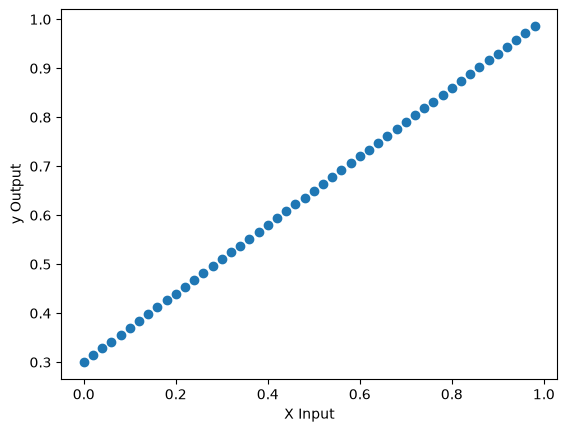

In [37]:
plt.scatter(X , y)
plt.xlabel("X Input")
plt.ylabel("y Output")
plt.show()

In [38]:
len(X) , len(y)

(50, 50)

In [39]:
train_split = int(len(X) * 0.8)
#Train Test Split
X_train , y_train = X[:train_split] , y[:train_split]
X_test , y_test = X[train_split:] , y[train_split:]


In [40]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(1 , requires_grad=True)) #nn.Parameter = This tensor is a learnable parameter of my model.
        self.bias = nn.Parameter(torch.randn(1 , requires_grad=True)) #requires grad = track operations in this tensor so it can calculate its gradients.
    
    def forward(self , x):
        return self.weights * x + self.bias
    
        

In [41]:
#random Seed
torch.manual_seed(42) #makes the random initialization reproducible.
model = LinearRegressionModel()

print(model.state_dict())
print(list(model.parameters()))

OrderedDict({'weights': tensor([0.3367]), 'bias': tensor([0.1288])})
[Parameter containing:
tensor([0.3367], requires_grad=True), Parameter containing:
tensor([0.1288], requires_grad=True)]


In [42]:
# y = 0.3367x + 0.1288

In [ ]:
with torch.no_grad():
    y_predicts = model(X_test) #unseen Data -> X test

In [52]:
#FUNCTION TO PLOT GRAPH
def plot_the_graph(train_data = X_train , 
                   train_labels=y_train , 
                   test_data = X_test , 
                   test_labels = y_test , 
                   predictions=None):
    plt.figure(figsize=(10,9))
    plt.scatter(train_data, train_labels,
                c="b", label="Training data")

    plt.scatter(test_data, test_labels,
                c="g", label="Testing data")

    if predictions is not None:
        plt.scatter(test_data, predictions,
                    c="r", label="Predictions")

    plt.legend()
    plt.show()
   

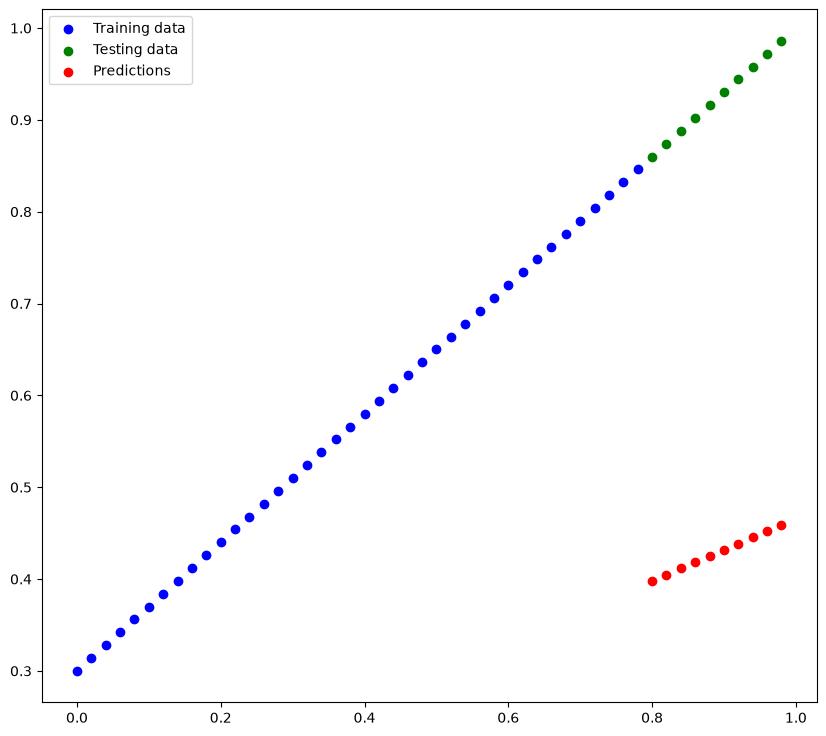

In [53]:
plot_the_graph(predictions=y_predicts)

In [54]:
loss_fn = nn.L1Loss() #Mean Absolute Error Loss Function
y_predicts = model(X_train) #Seen Data

In [56]:
loss = loss_fn(y_predicts , y_train)
print(loss)

tensor(0.3129, grad_fn=<MeanBackward0>)


In [ ]:
optimizer = torch.optim.SGD(
    params = model.parameters(), #We will optimize these parameters
    lr = 0.01
)

In [ ]:
loss.backward() #It computes the gradients.

In [59]:
optimizer.step() #optimizer.step() = It updates the parameters using those gradients.

In [ ]:
epochs = 100

for epoch in range(epochs):

    # 1. Training mode
    model.train()

    # 2. Forward pass
    y_pred = model(X_train) 

    # 3. Calculate loss
    loss = loss_fn(y_pred, y_train) #training

    # 4. Clear old gradients
    optimizer.zero_grad() #Remove gradients from the previous training iteration.

    # 5. Backpropagation
    loss.backward()

    # 6. Update parameters
    optimizer.step() 

    print(f"Epoch: {epoch} | Loss: {loss.item()}")

Epoch: 0 | Loss: 0.3013603389263153
Epoch: 1 | Loss: 0.28983935713768005
Epoch: 2 | Loss: 0.2783183455467224
Epoch: 3 | Loss: 0.26679736375808716
Epoch: 4 | Loss: 0.2552763521671295
Epoch: 5 | Loss: 0.24375534057617188
Epoch: 6 | Loss: 0.23223432898521423
Epoch: 7 | Loss: 0.22071333229541779
Epoch: 8 | Loss: 0.20919232070446014
Epoch: 9 | Loss: 0.1976713240146637
Epoch: 10 | Loss: 0.18615034222602844
Epoch: 11 | Loss: 0.1746293306350708
Epoch: 12 | Loss: 0.16310831904411316
Epoch: 13 | Loss: 0.1515873372554779
Epoch: 14 | Loss: 0.14006635546684265
Epoch: 15 | Loss: 0.1285453587770462
Epoch: 16 | Loss: 0.11702437698841095
Epoch: 17 | Loss: 0.1060912236571312
Epoch: 18 | Loss: 0.09681284427642822
Epoch: 19 | Loss: 0.08908725529909134
Epoch: 20 | Loss: 0.08227583020925522
Epoch: 21 | Loss: 0.07638873159885406
Epoch: 22 | Loss: 0.07160007208585739
Epoch: 23 | Loss: 0.06747635453939438
Epoch: 24 | Loss: 0.06395438313484192
Epoch: 25 | Loss: 0.06097004935145378
Epoch: 26 | Loss: 0.0584581904

In [ ]:
model.eval() #Switches the PyTorch model from training mode to evaluation mode.

with torch.inference_mode(): #Temporarily disables gradient calculation and enables internal memory/speed optimizations.
    
    y_predicts_after = model(X_test)
    test_loss = loss_fn(y_predicts_after , y_test)

print(f"The loss {test_loss.item()}")

The loss 0.05646304413676262


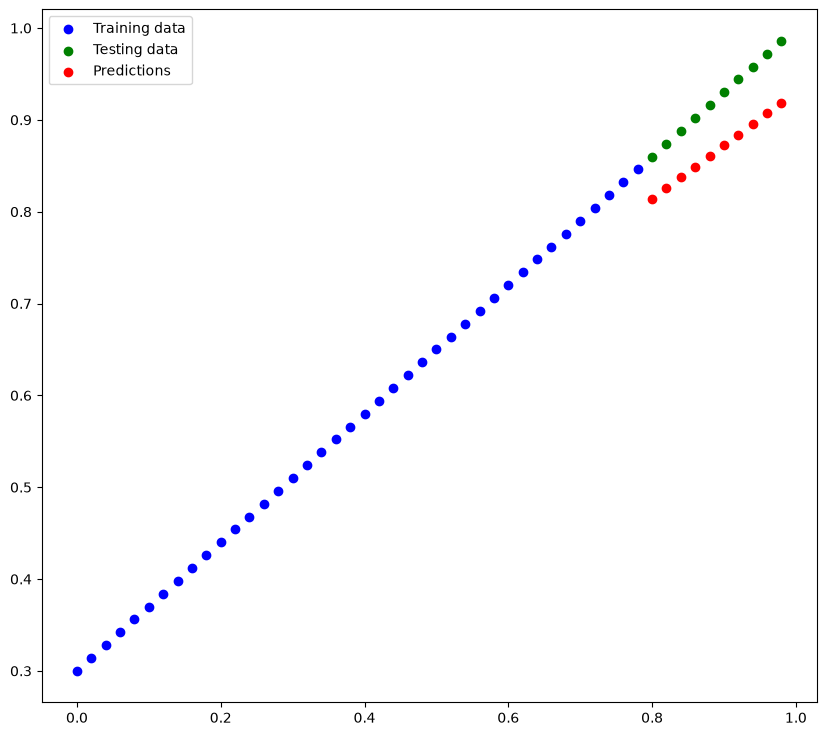

In [69]:
plot_the_graph(predictions=y_predicts_after)

In [70]:
print("\nModel Results")
print("Learned weights:", model.weights.item())
print("Learned bias:", model.bias.item())
print("Test loss:", test_loss.item())


Model Results
Learned weights: 0.5800304412841797
Learned bias: 0.3503098785877228
Test loss: 0.05646304413676262


In [71]:
torch.save(
    model.state_dict(),
    "LinearRegressionModelParam.pth"
)
